In [6]:
import os

os.environ["PYTHONPATH"] = "."

os.chdir(r"C:\Users\tnhom\Desktop\CV\Final_project\workspace")
print(os.getcwd())


C:\Users\tnhom\Desktop\CV\Final_project\workspace


In [3]:
import os
import glob
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from torchvision.datasets import ImageFolder

# 設定路徑與超參數
DATA_DIR = "dataset/imgs"  # 內含 train/ 與 test/
BATCH_SIZE = 64
EPOCHS = 3
LR = 0.001

# 自動偵測是否具備 GPU 加速
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {DEVICE}")

Using device: cuda


In [8]:
from torch.utils.data import random_split
from torchvision.datasets import ImageFolder

# 基礎前處理：縮放並轉為 PyTorch 張量
transform = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
])

# 讀取完整訓練資料
full_dataset = ImageFolder(root=os.path.join(DATA_DIR, "train"), transform=transform)

# 切分訓練集與驗證集
val_size = int(len(full_dataset) * 0.2)
train_size = len(full_dataset) - val_size
train_subset, val_subset = random_split(
    full_dataset,
    [train_size, val_size],
    generator=torch.Generator().manual_seed(42)
)

train_loader = DataLoader(train_subset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
val_loader = DataLoader(val_subset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

print(f"Train samples: {len(train_subset)}, Val samples: {len(val_subset)}")


Train samples: 17940, Val samples: 4484


In [9]:
class SimpleCNN(nn.Module):
    def __init__(self):
        super(SimpleCNN, self).__init__()
        # 特徵提取層
        self.conv_layers = nn.Sequential(
            nn.Conv2d(3, 16, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2),  # 64x64 -> 32x32
            nn.Conv2d(16, 32, kernel_size=3, padding=1),
            nn.ReLU(),
            nn.MaxPool2d(2, 2)   # 32x32 -> 16x16
        )
        # 分類輸出層
        self.fc_layers = nn.Sequential(
            nn.Flatten(),
            nn.Linear(32 * 16 * 16, 64),
            nn.ReLU(),
            nn.Linear(64, 10)     # 輸出 10 個類別
        )

    def forward(self, x):
        x = self.conv_layers(x)
        x = self.fc_layers(x)
        return x

model = SimpleCNN().to(DEVICE)
print(model)


SimpleCNN(
  (conv_layers): Sequential(
    (0): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (1): ReLU()
    (2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
    (3): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
    (4): ReLU()
    (5): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  )
  (fc_layers): Sequential(
    (0): Flatten(start_dim=1, end_dim=-1)
    (1): Linear(in_features=8192, out_features=64, bias=True)
    (2): ReLU()
    (3): Linear(in_features=64, out_features=10, bias=True)
  )
)


In [11]:
print(f"Full samples:{len(full_dataset)}, Train samples: {len(train_subset)}, Val samples: {len(val_subset)}")

Full samples:22424, Train samples: 17940, Val samples: 4484


In [10]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model.parameters(), lr=LR)

print("Start Training...")
model.train()

for epoch in range(EPOCHS):
    total_loss = 0.0
    for images, labels in train_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = model(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(train_loader)
    print(f"Epoch [{epoch+1}/{EPOCHS}], Loss: {avg_loss:.4f}")


Start Training...
Epoch [1/3], Loss: 1.0610
Epoch [2/3], Loss: 0.1578
Epoch [3/3], Loss: 0.0679


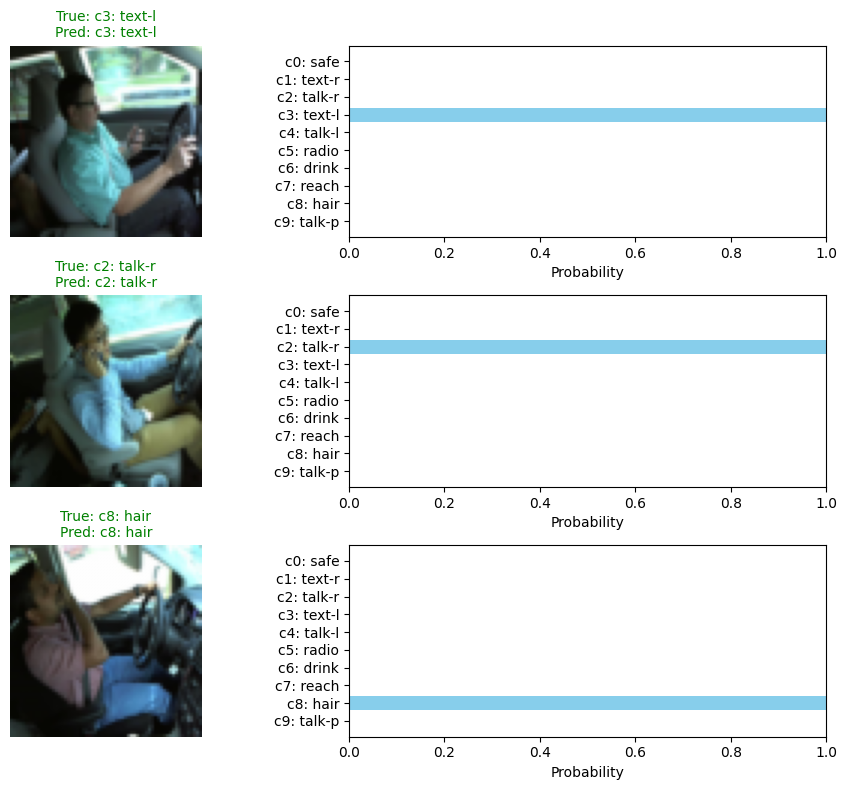

In [11]:
import matplotlib.pyplot as plt
import numpy as np
import torch

CLASS_NAMES = ['c0: safe', 'c1: text-r', 'c2: talk-r', 'c3: text-l', 'c4: talk-l',
               'c5: radio', 'c6: drink', 'c7: reach', 'c8: hair', 'c9: talk-p']

# 隨機抽取 3 個驗證集索引 (也可指定特定 index)
indices = np.random.choice(len(val_subset), size=3, replace=False)

fig, axes = plt.subplots(3, 2, figsize=(10, 8))
model.eval()

with torch.no_grad():
    for row_idx, idx in enumerate(indices):
        img_tensor, true_label = val_subset[idx]

        # 增加 batch 維度送進模型並計算 Softmax 機率
        input_tensor = img_tensor.unsqueeze(0).to(DEVICE)
        output = model(input_tensor)
        probs = torch.softmax(output, dim=1).squeeze(0).cpu().numpy()
        pred_class = np.argmax(probs)

        # 判斷是否預測正確以顯示不同顏色標題
        is_correct = (pred_class == true_label)
        color = 'green' if is_correct else 'red'

        # 左邊：原圖
        img_np = img_tensor.permute(1, 2, 0).cpu().numpy()
        axes[row_idx, 0].imshow(img_np)
        title_text = f"True: {CLASS_NAMES[true_label]}\nPred: {CLASS_NAMES[pred_class]}"
        axes[row_idx, 0].set_title(title_text, color=color, fontsize=10)
        axes[row_idx, 0].axis('off')

        # 右邊：10 類機率長條圖 (預測正確標天藍色，預測錯誤標粉紅色)
        bar_color = 'skyblue' if is_correct else 'lightcoral'
        axes[row_idx, 1].barh(CLASS_NAMES, probs, color=bar_color)
        axes[row_idx, 1].set_xlim(0, 1.0)
        axes[row_idx, 1].set_xlabel('Probability')
        axes[row_idx, 1].invert_yaxis()

plt.tight_layout()
plt.show()

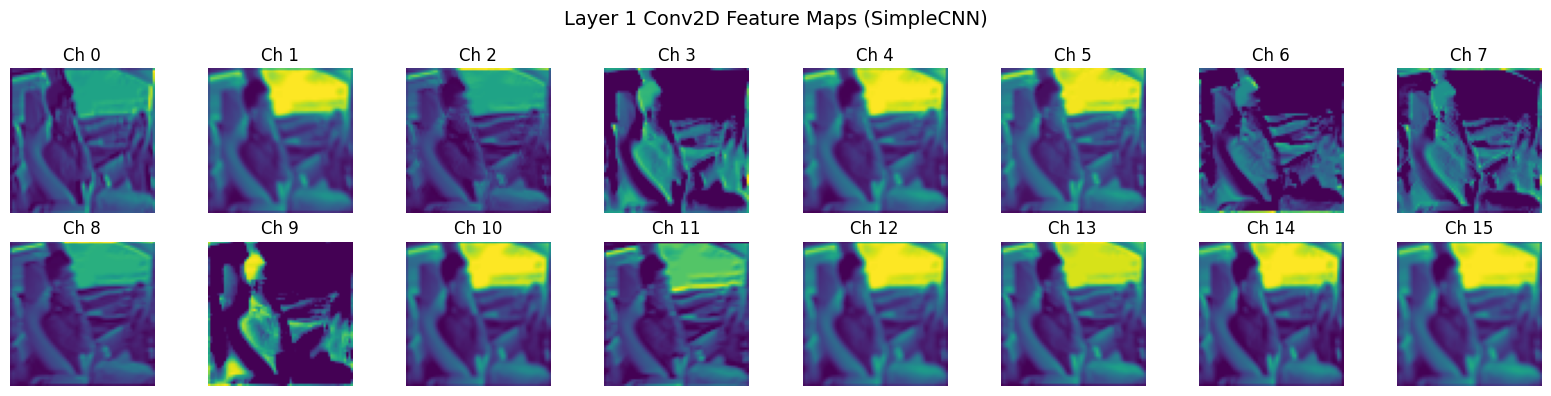

In [12]:
import matplotlib.pyplot as plt

# 挑選訓練集的第一張圖
sample_img, _ = train_subset[0]
sample_tensor = sample_img.unsqueeze(0).to(DEVICE)

# 抓取第一層卷積 + ReLU 的輸出
with torch.no_grad():
    feat_map = model.conv_layers[0](sample_tensor)  # Conv2d(3, 16)
    feat_map = model.conv_layers[1](feat_map)       # ReLU

feat_map = feat_map.squeeze(0).cpu().numpy()  # 形狀為 (16, 64, 64)

# 繪製 16 個通道的特徵圖
fig, axes = plt.subplots(2, 8, figsize=(16, 4))
for i, ax in enumerate(axes.flat):
    ax.imshow(feat_map[i], cmap='viridis')
    ax.set_title(f"Ch {i}")
    ax.axis('off')

plt.suptitle("Layer 1 Conv2D Feature Maps (SimpleCNN)", fontsize=14)
plt.tight_layout()
plt.show()


亮色區塊  : 神經元處於高激活（Activation）狀態

暗色區塊 : 代表卷積核對該區域沒有反應，屬於被過濾掉的背景或無關資訊

In [13]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, classification_report

model.eval()
all_preds = []
all_targets = []

with torch.no_grad():
    for images, labels in val_loader:
        images = images.to(DEVICE)
        outputs = model(images)
        preds = torch.argmax(outputs, dim=1).cpu().numpy()

        all_preds.extend(preds)
        all_targets.extend(labels.numpy())

all_preds = np.array(all_preds)
all_targets = np.array(all_targets)

# 1. 計算 Overall Accuracy
val_acc = accuracy_score(all_targets, all_preds)

# 2. 計算 F1-Score
# macro: 每個類別權重相同 (最能反映少數類別或難分類別的真實表現)
# weighted: 依類別樣本數量加權
val_f1_macro = f1_score(all_targets, all_preds, average='macro')
val_f1_weighted = f1_score(all_targets, all_preds, average='weighted')

print(f"Validation Accuracy: {val_acc * 100:.2f}%")
print(f"Validation Macro F1: {val_f1_macro:.4f}")
print(f"Validation Weighted F1: {val_f1_weighted:.4f}\n")

# 印出 c0 ~ c9 每一類的詳細 Precision, Recall, F1-score
class_names = [f"c{i}" for i in range(10)]
print(classification_report(all_targets, all_preds, target_names=class_names, digits=4))


Validation Accuracy: 97.97%
Validation Macro F1: 0.9796
Validation Weighted F1: 0.9797

              precision    recall  f1-score   support

          c0     0.9868    0.9332    0.9592       479
          c1     0.9873    0.9915    0.9894       469
          c2     0.9808    0.9957    0.9882       462
          c3     0.9554    0.9958    0.9752       473
          c4     0.9614    0.9916    0.9763       477
          c5     0.9955    0.9911    0.9933       448
          c6     0.9958    0.9772    0.9864       483
          c7     0.9949    0.9872    0.9910       392
          c8     0.9601    0.9704    0.9652       372
          c9     0.9810    0.9627    0.9718       429

    accuracy                         0.9797      4484
   macro avg     0.9799    0.9796    0.9796      4484
weighted avg     0.9800    0.9797    0.9797      4484



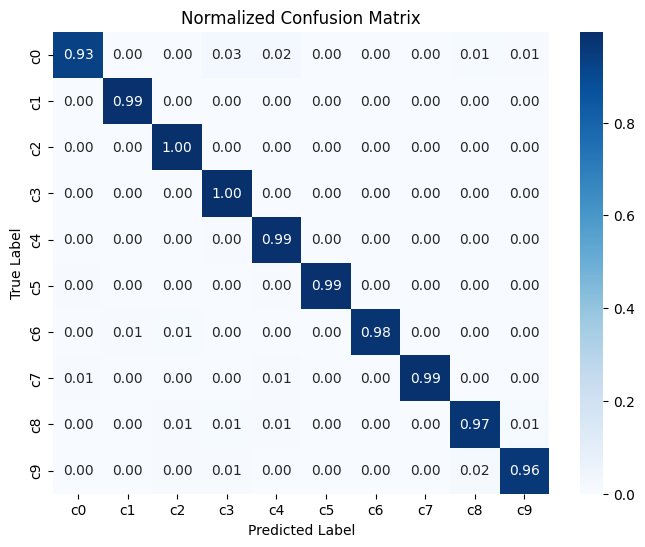

In [14]:
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(all_targets, all_preds)
cm_normalized = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]  # 正規化為比率

plt.figure(figsize=(8, 6))
sns.heatmap(cm_normalized, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=[f"c{i}" for i in range(10)],
            yticklabels=[f"c{i}" for i in range(10)])
plt.xlabel('Predicted Label')
plt.ylabel('True Label')
plt.title('Normalized Confusion Matrix')
plt.show()


以下跑正式題目，用 train set 全部跑過模型

In [16]:
model2 = SimpleCNN().to(DEVICE)
full_loader = DataLoader(full_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)


criterion = nn.CrossEntropyLoss()
optimizer = optim.Adam(model2.parameters(), lr=LR)

print("Start Training...")
model2.train()

for epoch in range(EPOCHS):
    total_loss = 0.0
    for images, labels in full_loader:
        images, labels = images.to(DEVICE), labels.to(DEVICE)

        optimizer.zero_grad()
        outputs = model2(images)
        loss = criterion(outputs, labels)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    avg_loss = total_loss / len(full_loader)
    print(f"Epoch [{epoch+1}/{EPOCHS}], Loss: {avg_loss:.4f}")

Start Training...
Epoch [1/3], Loss: 0.9558
Epoch [2/3], Loss: 0.1371
Epoch [3/3], Loss: 0.0696


In [15]:
# 定義測試集 Dataset 類別
class TestDataset(Dataset):
    def __init__(self, file_paths, transform=None):
        self.file_paths = file_paths
        self.transform = transform

    def __len__(self):
        return len(self.file_paths)

    def __getitem__(self, idx):
        img_path = self.file_paths[idx]
        image = Image.open(img_path).convert("RGB")
        if self.transform:
            image = self.transform(image)
        filename = os.path.basename(img_path)
        return image, filename


In [17]:
print("Generating Submission...")

# 抓取所有測試集影像路徑
test_image_paths = sorted(glob.glob(os.path.join(DATA_DIR, "test", "*.jpg")))
test_dataset = TestDataset(test_image_paths, transform=transform)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

model.eval()
results = []

with torch.no_grad():
    for images, filenames in test_loader:
        images = images.to(DEVICE)
        outputs = model(images)

        # Softmax 換算為 10 類的預測機率
        probs = torch.softmax(outputs, dim=1).cpu().numpy()

        for fname, prob in zip(filenames, probs):
            row = {"img": fname}
            for i in range(10):
                row[f"c{i}"] = prob[i]
            results.append(row)

# 依 Kaggle 規範重組欄位順序並存檔
submission_df = pd.DataFrame(results)
columns = ["img"] + [f"c{i}" for i in range(10)]
submission_df = submission_df[columns]
submission_df.to_csv("submission.csv", index=False)

print("Finished! 'submission.csv' generated successfully.")


Generating Submission...
Finished! 'submission.csv' generated successfully.


上傳並評分

In [20]:
!kaggle competitions submit -c state-farm-distracted-driver-detection -f submission.csv -m "Simple CNN baseline 3 epochs"

100% 10.8M/10.8M [00:01<00:00, 7.60MB/s]
Successfully submitted to State Farm Distracted Driver Detection

查詢最新評分

評分標準 : $Log Loss = - (1 / N) * Σ_{i=1}^N Σ_{j=0}^9 y_{ij} * log(p_{ij})$

分數越低越好，分數意義如下：
| 分數區間 (Log Loss) | 水平代表意義與模型狀態 |
| :--- | :--- |
| **~ 2.30** | **完全盲猜基準線**：對所有類別輸出均勻機率 $0.1$（$-\ln(0.1) \approx 2.30259$）。 |
| **2.90 ~ 3.10** | **極簡 Baseline（未校準）**：淺層卷積模型在少數 Epochs 下訓練，因圖片解析度過低且未處理過擬合與機率校準，對未見過駕駛猜錯時受到嚴重懲罰。 |
| **1.00 ~ 1.50** | **標準 CNN 充分訓練**：使用標準卷積網路（如 ResNet-18 / ResNet-34）經標準資料增強並收斂後的典型表現。 |
| **0.30 ~ 0.50** | **專題預期目標區間**：採用 ResNet-50 骨幹結合 GroupKFold 駕駛員獨立切分、CBAM 空間/通道注意力機制與 Label Smoothing 標籤平滑後的穩定水準。 |
| **0.10 ~ 0.20** | **Kaggle 頂尖／獲獎水準**：多模型融合（Ensemble，結合 CNN 與 Vision Transformer）並搭配測試階段增強（TTA）與精細機率校準。 |

In [21]:
!kaggle competitions submissions -c state-farm-distracted-driver-detection

fileName        date                        description                   status                     publicScore  privateScore  
--------------  --------------------------  ----------------------------  -------------------------  -----------  ------------  
submission.csv  2026-11-10 11:02:29.277000  Simple CNN baseline 3 epochs  SubmissionStatus.COMPLETE  3.03181      2.94071       


檢查分類結果合理性，建議在上傳評分前做

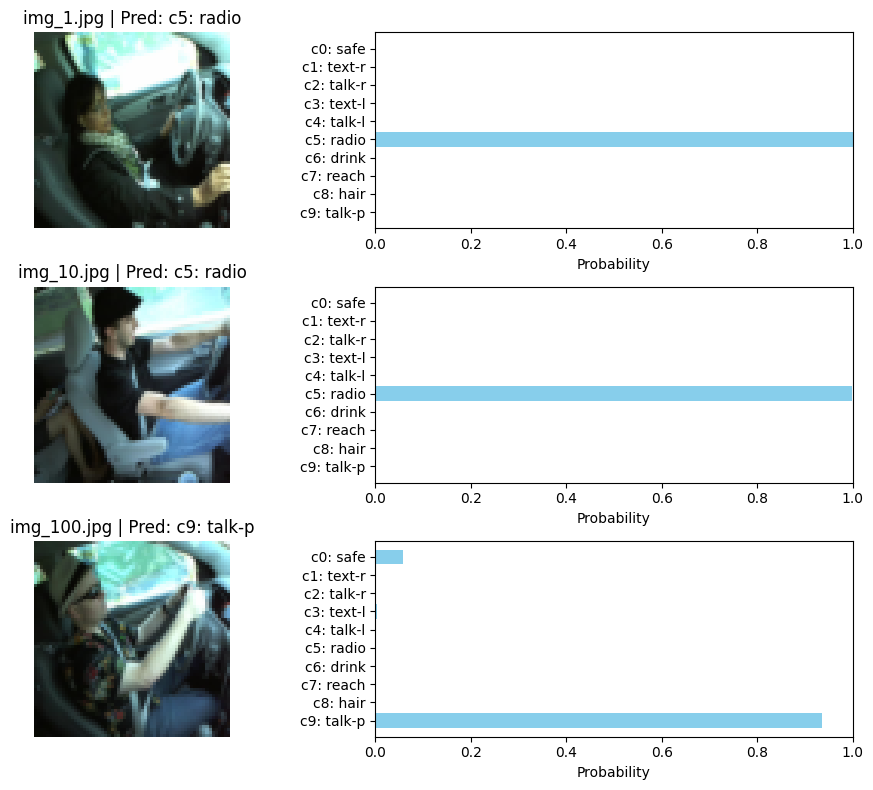

In [18]:
import matplotlib.pyplot as plt
import numpy as np

CLASS_NAMES = ['c0: safe', 'c1: text-r', 'c2: talk-r', 'c3: text-l', 'c4: talk-l',
               'c5: radio', 'c6: drink', 'c7: reach', 'c8: hair', 'c9: talk-p']

# 隨機抽取 3 個推論樣本做視覺化
fig, axes = plt.subplots(3, 2, figsize=(10, 8))

for idx in range(3):
    img_tensor, filename = test_dataset[idx]
    # 取出對應的預測機率
    probs = submission_df[submission_df['img'] == filename][[f'c{i}' for i in range(10)]].values[0]
    pred_class = np.argmax(probs)

    # 左邊：原圖 (反正規化回 0~1)
    img_np = img_tensor.permute(1, 2, 0).cpu().numpy()
    axes[idx, 0].imshow(img_np)
    axes[idx, 0].set_title(f"{filename} | Pred: {CLASS_NAMES[pred_class]}")
    axes[idx, 0].axis('off')

    # 右邊：10 類機率長條圖
    axes[idx, 1].barh(CLASS_NAMES, probs, color='skyblue')
    axes[idx, 1].set_xlim(0, 1.0)
    axes[idx, 1].set_xlabel('Probability')
    axes[idx, 1].invert_yaxis()

plt.tight_layout()
plt.show()


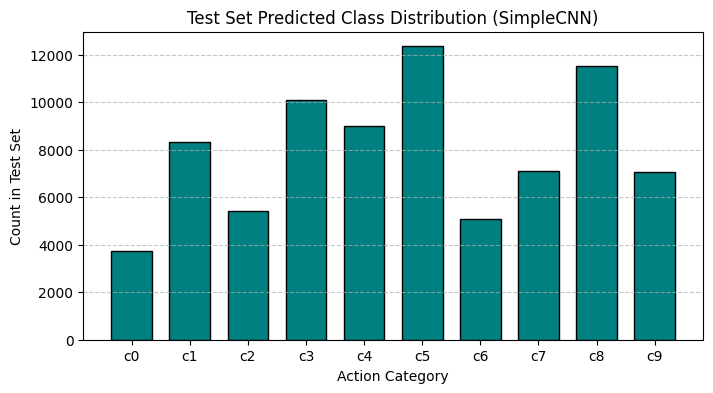

In [19]:
import matplotlib.pyplot as plt
import numpy as np

# 取出測試集每張圖最高機率的類別
pred_indices = np.argmax(submission_df[[f'c{i}' for i in range(10)]].values, axis=1)

plt.figure(figsize=(8, 4))
plt.hist(pred_indices, bins=np.arange(11) - 0.5, rwidth=0.7, color='teal', edgecolor='black')
plt.xticks(range(10), [f'c{i}' for i in range(10)])
plt.xlabel('Action Category')
plt.ylabel('Count in Test Set')
plt.title('Test Set Predicted Class Distribution (SimpleCNN)')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.show()
